# 08 · PET — Other Tracers (Pilot Substudies)
> *Small-N exploratory PET substudies: neuroinflammation (DPA-714), and novel experimental tracers (FD4, MNI1008, C05-05).*

## Background: What Are These Tracers?

PPMI includes several very small **pilot PET substudies** testing novel tracers that target different aspects of PD biology.

| Tracer | Target | Mechanism | Why it matters |
|--------|--------|-----------|---------------|
| **DPA-714** (¹⁸F) | TSPO | Binds to Translocator Protein on activated microglia | **Neuroinflammation** — microglia become activated in PD; may drive disease progression |
| **FD4** (¹⁸F) | Unknown/Novel | Experimental tracer | Under evaluation — specific target being characterised |
| **MNI1008** (¹⁸F) | Likely α-synuclein related | Novel compound from Montreal Neurological Institute | **Alpha-synuclein** (the protein that forms Lewy bodies in PD) is the ultimate PD biomarker target |
| **C05-05** (¹⁸F) | Novel | Experimental | Under evaluation |

**Key context:**
- These are **feasibility/safety studies** — the goal is to show the tracer works in humans, not to establish clinical utility yet
- **N = 6–16 participants** — not suitable for statistical analysis
- Data is primarily acquisition metadata and completion records

> ⚠️ All findings from these substudies should be treated as **hypothesis-generating pilot data only.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 14,
                     'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'figure.dpi': 120})
DATA_DIR = Path('../Imaging')
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/asadriaz/Desktop/PPMI Imaging/Imaging


In [2]:
VISIT_ORDER = ['SC', 'BL', 'V04', 'V06', 'V08', 'V10', 'V12', 'V14', 'V16', 'PW']
VISIT_LABELS = {'SC': 'Screening', 'BL': 'Baseline', 'PW': 'Withdrawal',
                'V04': 'Yr 1', 'V06': 'Yr 2', 'V08': 'Yr 3',
                'V10': 'Yr 4', 'V12': 'Yr 5', 'V14': 'Yr 6', 'V16': 'Yr 7'}
def ordered_visits(series):
    present = series.dropna().unique().tolist()
    ordered = [v for v in VISIT_ORDER if v in present]
    return ordered + sorted([v for v in present if v not in VISIT_ORDER])

## Load All Four Files

In [3]:
dpa714  = pd.read_csv(DATA_DIR / 'Dual_PET_DPA-714_Imaging_Substudy_DPA-714_NX_PET_Imaging_12Nov2026.csv')
fd4     = pd.read_csv(DATA_DIR / 'FD4_Tracer_Substudy_FD4_PET_Imaging_12Nov2026.csv')
mni1008 = pd.read_csv(DATA_DIR / 'MNI1008_PET_Imaging_Substudy_MNI_PET_Imaging_12Nov2026.csv')
c05     = pd.read_csv(DATA_DIR / 'C05-05_PET_Imaging_Substudy_Imaging_12Nov2026.csv')

dfs = {'DPA-714 (Neuroinflammation)': dpa714, 'FD4 (Novel)': fd4,
       'MNI1008 (Novel)': mni1008, 'C05-05 (Novel)': c05}
for name, df in dfs.items():
    print(f'{name:35s}: {len(df):>3} rows | {df["PATNO"].nunique()} participants | {df.shape[1]} cols')

DPA-714 (Neuroinflammation)        :  10 rows | 10 participants | 9 cols
FD4 (Novel)                        :  16 rows | 11 participants | 32 cols
MNI1008 (Novel)                    :   6 rows | 6 participants | 30 cols
C05-05 (Novel)                     :  10 rows | 10 participants | 21 cols


## Participant and Visit Summary

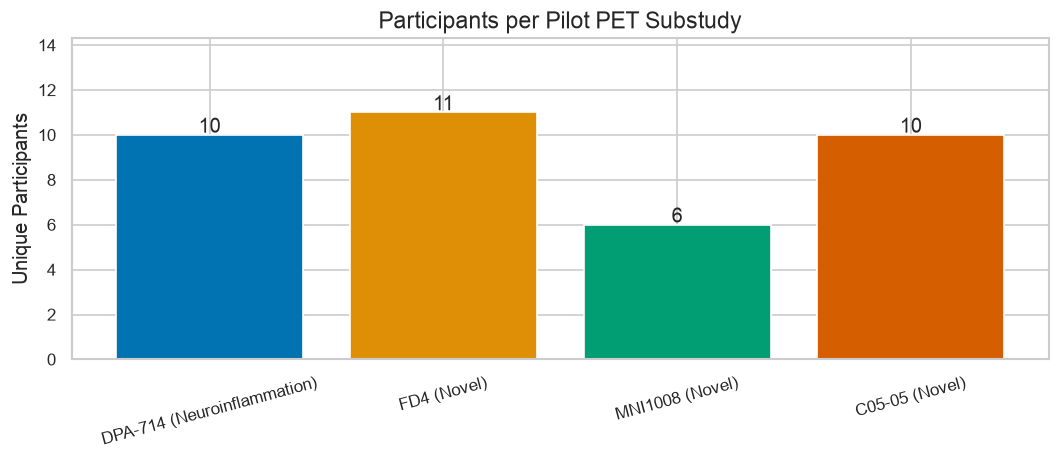

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
names = list(dfs.keys())
counts = [df['PATNO'].nunique() for df in dfs.values()]
colors = sns.color_palette('colorblind', len(names))
bars = ax.bar(names, counts, color=colors)
ax.set_title('Participants per Pilot PET Substudy')
ax.set_ylabel('Unique Participants')
ax.tick_params(axis='x', rotation=15)
for b, v in zip(bars, counts):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.1, str(v), ha='center', fontsize=12)
ax.set_ylim(0, max(counts)*1.3)
plt.tight_layout(); plt.show()

## Column Overview — What Data Is Available?

Since these are small substudies, we inspect available columns and completion flags rather than analysing distributions.

In [5]:
for name, df in dfs.items():
    print(f'\n{"="*60}')
    print(f'{name}')
    print(f'{"="*60}')
    print(f'Shape: {df.shape}')
    print('\nColumns and types:')
    for col in df.columns:
        dtype = df[col].dtype
        n_unique = df[col].nunique()
        sample = df[col].dropna().iloc[0] if len(df[col].dropna()) > 0 else 'NaN'
        print(f'  {col:35s} {str(dtype):10s} nunique={n_unique:3d}  sample={str(sample)[:30]}')


DPA-714 (Neuroinflammation)
Shape: (10, 9)

Columns and types:
  REC_ID                              str        nunique= 10  sample=IA1039370
  PATNO                               int64      nunique= 10  sample=53258
  EVENT_ID                            str        nunique=  7  sample=R14
  SUB_EVENT_ID                        str        nunique=  1  sample=BL-DPDPA
  PAG_NAME                            str        nunique=  1  sample=DPDPAIMAG
  INFODT                              str        nunique=  3  sample=05/2026
  DPANXCMPLT                          int64      nunique=  1  sample=1
  ORIG_ENTRY                          str        nunique=  3  sample=05/2026
  LAST_UPDATE                         str        nunique=  7  sample=2026-05-27

FD4 (Novel)
Shape: (16, 32)

Columns and types:
  REC_ID                              str        nunique= 16  sample=IA1165105
  PATNO                               int64      nunique= 11  sample=3464
  EVENT_ID                            str    

## Scan Completion Summary

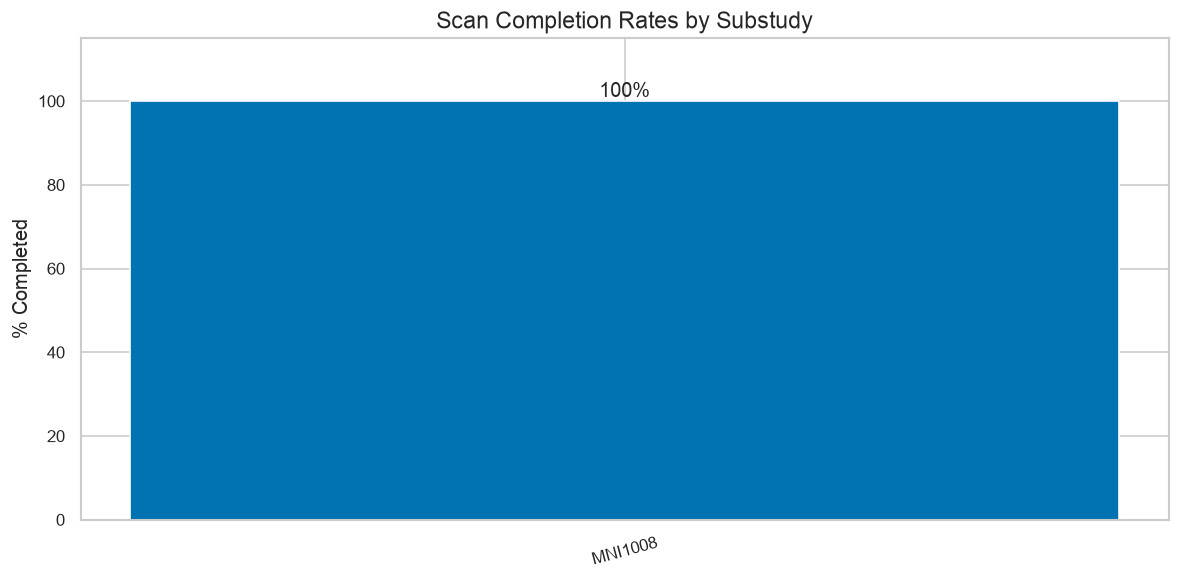

In [6]:
complete_flags = ['PETCMPLT','AVNEXCMPLT','AVCONVCMPLT','CMPLT','COMPLETE']

fig, ax = plt.subplots(figsize=(10, 5))
summary_rows = []
for name, df in dfs.items():
    for flag in complete_flags:
        if flag in df.columns:
            pct = (df[flag] == 1).mean() * 100 if df[flag].dtype in [int, np.int64] else                   (df[flag].astype(str).str.lower().isin(['yes','1','true'])).mean() * 100
            summary_rows.append({'Substudy': name.split('(')[0].strip(),
                                  'Flag': flag, 'Complete%': pct})
            break

if summary_rows:
    summ_df = pd.DataFrame(summary_rows)
    bars = ax.bar(summ_df['Substudy'], summ_df['Complete%'],
                  color=sns.color_palette('colorblind', len(summ_df)))
    ax.set_title('Scan Completion Rates by Substudy')
    ax.set_ylabel('% Completed'); ax.set_ylim(0, 115)
    ax.tick_params(axis='x', rotation=15)
    for b, v in zip(bars, summ_df['Complete%']):
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+1, f'{v:.0f}%', ha='center')
    plt.tight_layout(); plt.show()
else:
    print('No standard completion flag found — checking raw column values:')
    for name, df in dfs.items():
        print(f'\n{name}:'); print(df.dtypes.to_string())

## Vital Signs (where available)

Larger substudy files (FD4, MNI1008) collect multiple timepoints of vital signs.

In [7]:
vital_map = {
    'Systolic BP': ['SYSSUPBF','SYSSUPAF','SYS_SUP_BL','SYS_BL'],
    'Diastolic BP': ['DIASUPBF','DIASUPAF','DIAS_SUP_BL'],
    'Heart Rate': ['HRSUPBF','HRSUPAF','HR_SUP_BL'],
}
for name, df in [('FD4', fd4), ('MNI1008', mni1008)]:
    found = [(vname, [c for c in alts if c in df.columns])
             for vname, alts in vital_map.items()]
    found = [(vname, cols) for vname, cols in found if cols]
    if found:
        print(f'\n{name} vital signs:')
        for vname, cols in found:
            print(f'  {vname}: {df[cols].describe().round(1).loc["mean"].to_dict()}')


FD4 vital signs:
  Systolic BP: {'SYSSUPBF': 143.5, 'SYSSUPAF': 145.8}
  Diastolic BP: {'DIASUPBF': 82.1, 'DIASUPAF': 82.4}
  Heart Rate: {'HRSUPBF': 65.6, 'HRSUPAF': 64.6}

MNI1008 vital signs:
  Systolic BP: {'SYSSUPBF': 143.3, 'SYSSUPAF': 141.8}
  Diastolic BP: {'DIASUPBF': 83.7, 'DIASUPAF': 82.8}
  Heart Rate: {'HRSUPBF': 61.7, 'HRSUPAF': 58.5}


## Key Takeaways

- **All four substudies are pilot studies** — small N (6–16 participants), unsuitable for independent statistical analysis
- **DPA-714** targets neuroinflammation (microglial activation via TSPO) — highly relevant to PD disease mechanisms
- **MNI1008** likely targets alpha-synuclein — the definitive PD pathological protein; if validated, would be the most disease-specific PD PET tracer ever
- **FD4 and C05-05** are under characterisation — their exact clinical utility is being established
- **These substudies represent the frontier** of PD biomarker research — their data is precious precisely because it's rare
- **For analysis:** combine with DaTSCAN/clinical data for context, treat as case series rather than cohort studies